# NASA Exoplanet Data Analysis

## Project Overview

This project explores NASA's exoplanet dataset using
Python to investigate planetary characteristics,
discovery methods, and relationships between
astronomical variables.

## Objectives

1. Analyze the distribution of exoplanet radii and masses.
2. Identify host stars with the most known planets.
3. Examine the most common discovery methods.
4. Explore relationships between planet radius, mass,
   and orbital period.
5. Investigate how discovered planet sizes have
   changed over time.

## Tools and Libraries

Python, Pandas, Matplotlib, Seaborn, hvPlot, Plotly

## Dataset

Source: NASA Exoplanet Archive

## Column descriptions 
Below are the columns we use in the notebook and what they represent.

- **pl_name:** Planet name (string)
- **pl_rade:** Planet radius in Earth radii (float)
- **pl_bmasse:** Planet mass in Earth masses (float)
- **discoverymethod:** Discovery method (categorical — e.g., Transit, Radial Velocity)
- **hostname:** Host star name (string)
- **disc_year:** Discovery year (datetime)

## 1. Load Data

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hvplot.pandas 
import plotly.express as px

In [2]:
df = pd.read_csv(Path(r'udacity_exoplanet.csv'))

In [3]:
print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (1653, 7)


,pl_name,pl_rade,pl_bmasse,pl_orbper,discoverymethod,hostname,disc_year
0,55 Cnc e,1.933500,8.117035,0.736546,Radial Velocity,55 Cnc,2004
1,AU Mic b,4.070000,17.000000,8.463080,Transit,AU Mic,2020
2,AU Mic c,2.790000,13.600000,18.859018,Transit,AU Mic,2021
3,BD+20 594 b,2.355454,19.274050,41.685500,Transit,BD+20 594,2016
4,BD-14 3065 b,21.150600,3932.000000,4.288971,Transit,BD-14 3065 A,2024


## 2. Inspect the DataFrame
Use a suitable pandas method to inspect column dtypes and missing values.

In [4]:
#Inspect the dataframe
df.isnull().sum()

pl_name            0
pl_rade            0
pl_bmasse          0
pl_orbper          0
discoverymethod    0
hostname           0
disc_year          0
dtype: int64

## 3. Examine Numeric Summaries

Use a suitable pandas method to inspect numeric columns and distributions (e.g. count, mean, median, mode, etc.)


In [5]:
#Examine Numeric Summaries
df_numeric = df.select_dtypes(include='number')
df_numeric.describe()

,pl_rade,pl_bmasse,pl_orbper,disc_year
count,1653.000000,1653.000000,1.653000e+03,1653.000000
mean,7.866053,353.145978,2.518816e+05,2017.535995
std,5.997161,847.574427,9.890363e+06,5.036375
min,0.296310,0.100000,1.120067e-01,1999.000000
25%,2.395737,9.130000,3.196884e+00,2014.000000
50%,6.410000,67.400000,5.416108e+00,2018.000000
75%,12.860967,317.830000,1.412846e+01,2022.000000
max,65.850000,8899.195396,4.020000e+08,2025.000000


In [6]:
df_numeric.mode().iloc[0]

pl_rade         1.360000
pl_bmasse      12.500000
pl_orbper       0.112007
disc_year    2014.000000
Name: 0, dtype: float64

## 4. Create a Sorted List of Unique Planet and Host Star Names


In [7]:
#Create a sample of 20 unique planet names
planet_list=df['pl_name'].tolist()

unique_planets= sorted(set(planet_list))

print("First 20 of the unique planets: \n")

for planet in unique_planets[:20]:
    print(planet)

First 20 of the unique planets: 

55 Cnc e
AU Mic b
AU Mic c
BD+20 594 b
BD-14 3065 b
CFHTWIR-Oph 98 b
COCONUTS-2 b
CoRoT-1 b
CoRoT-10 b
CoRoT-11 b
CoRoT-12 b
CoRoT-13 b
CoRoT-14 b
CoRoT-16 b
CoRoT-17 b
CoRoT-18 b
CoRoT-19 b
CoRoT-2 b
CoRoT-20 b
CoRoT-21 b


In [8]:
#Create a sample of 20 unique host star names
hostname_list=df['hostname'].tolist()
unique_hostname= sorted(set(hostname_list))
print("First 20 of the unique host star names: \n")
for star in unique_hostname[:20]:
    print(star)


First 20 of the unique host star names: 

55 Cnc
AU Mic
BD+20 594
BD-14 3065 A
CFHTWIR-Oph 98 A
COCONUTS-2 A
CoRoT-1
CoRoT-10
CoRoT-11
CoRoT-12
CoRoT-13
CoRoT-14
CoRoT-16
CoRoT-17
CoRoT-18
CoRoT-19
CoRoT-2
CoRoT-20
CoRoT-21
CoRoT-22


## 5. Which THREE host stars have the MOST known planets?

In [9]:
#Determine the three host stars that have the most planets
planet_count={}
for i in df['hostname'].tolist():
    if i not in planet_count:
        planet_count[i]=1
    else:
        planet_count[i]+=1

planet_count_sort=dict(
    sorted(planet_count.items(),key=lambda x:x[1],reverse=True)[:3])
planet_count_sort

{'TRAPPIST-1': 7, 'HD 110067': 6, 'K2-138': 6}

## 6. Visual Inspection

### Histogram of planet radii

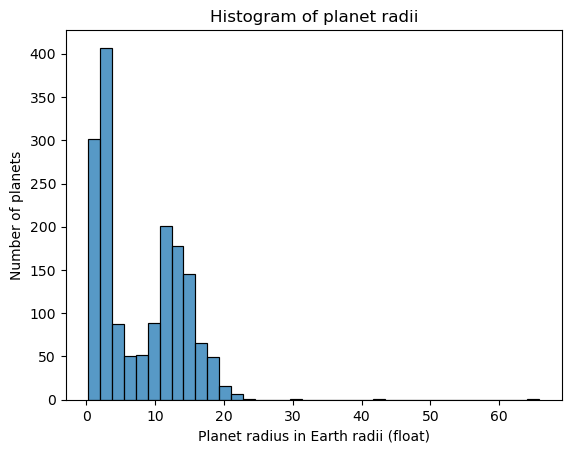

In [10]:
#Create a histogram of planet radii using seaborn
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['pl_rade'])
plt.title('Histogram of planet radii')
plt.xlabel('Planet radius in Earth radii (float)')
plt.ylabel('Number of planets')
plt.show()

### Bar Chart of Top Discovery Methods 

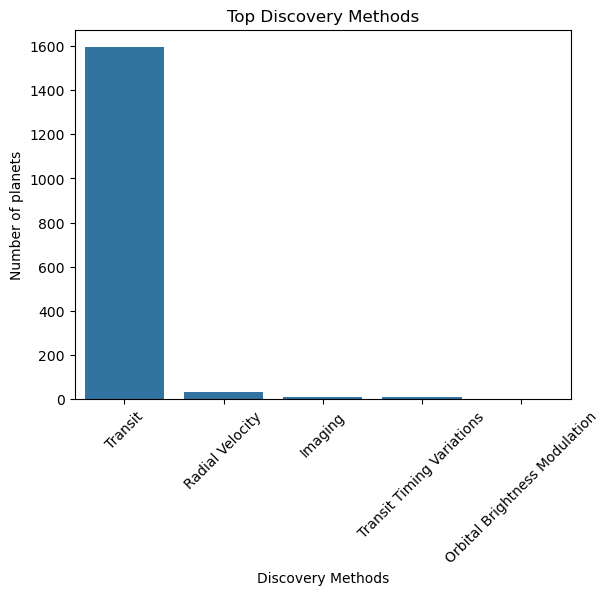

In [11]:
#Create a bar chart of the top discovery methods

discovery_method_values=df['discoverymethod'].value_counts().reset_index()

sns.barplot(x=discovery_method_values['discoverymethod'],y=discovery_method_values['count'])
plt.title('Top Discovery Methods')
plt.xlabel('Discovery Methods')
plt.ylabel('Number of planets')
plt.xticks(rotation=45)
plt.show()

### Scatter plot of Radius vs. Mass

In [12]:
#Create interactive scatter plot using hvplot with planet names on hover
import hvplot.pandas

df.hvplot.scatter(
x='pl_rade',
y='pl_bmasse',
by='discoverymethod',
hover_cols=['pl_name', 'hostname','disc_year'],
size=80,
title='Scatter Plot of Radius vs Mass',
xlabel='Planet Radius',
ylabel='Planet Mass')

:NdOverlay   [discoverymethod]
   :Scatter   [pl_rade]   (pl_bmasse,pl_name,hostname,disc_year)

### Boxplot of Orbital Periods


In [13]:
#Create interactive box plot using hvplot

df.hvplot.box(y='pl_orbper',
              logy=True,
              title='Distribution of Orbital Periods',
              ylabel='Orbital Period (Log)',
              width=600,
              height=400
             )

:BoxWhisker   (pl_orbper)

### Scatter plot of Radius vs. Discovery Year


In [14]:
#Create an interactive scatter plot using hvplot with planet names on hover
df.hvplot.scatter(x='disc_year',
                 y='pl_rade',
                 size=80,
                 title='Scatter Plot of Radius vs Discovery Year',
                 xlabel='Discovery Year',
                 ylabel='Planet Radius')

:Scatter   [disc_year]   (pl_rade)

## 7. Variable Relationships and Statistics

### Correlation Matrix of Numeric Variables 


In [15]:
#Create correlation matrix
df[['pl_rade','pl_bmasse','pl_orbper']].corr().style.background_gradient(cmap='coolwarm')

,pl_rade,pl_bmasse,pl_orbper
pl_rade,1.000000,0.353901,0.020235
pl_bmasse,0.353901,1.000000,0.059204
pl_orbper,0.020235,0.059204,1.000000


### Compute radius statistics by year


In [16]:
#Compute mean and median of planet radius per discovery year
#Show the first 10 years as a sample
df.groupby('disc_year')['pl_rade'].agg(['min','max','mean','median','std']).sort_index().head(10)

,min,max,mean,median,std
disc_year,,,,,
1999,15.468420,15.468420,15.468420,15.468420,NaN
2001,11.242627,11.242627,11.242627,11.242627,NaN
2002,14.571700,14.571700,14.571700,14.571700,NaN
2004,1.933500,13.955080,9.886131,12.117000,4.800995
2005,8.294660,12.767130,11.531903,12.532910,2.168635
2006,9.079000,14.533100,12.700952,13.518054,2.130701
2007,9.976000,20.075306,14.166143,14.751104,2.592677
2008,4.819870,20.456425,13.961444,13.849042,3.520814
2009,1.632500,21.208255,12.687245,13.332961,5.147093


## 8. Interactive visualization of radius statistics over time

In [17]:
#Create Interactive Line Plots

discover_year_group=df.groupby('disc_year')['pl_rade'].agg(['mean','median'])
discover_year_group['mode_radius']=df.groupby('disc_year')['pl_rade'].apply(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
discover_year_group.rename(columns={'mean':'mean_radius','median':'median_radius'},inplace=True)

discover_year_group=discover_year_group.reset_index()
mean_plot=discover_year_group.hvplot.line(x='disc_year',y='mean_radius',color='blue',label='Mean Planet Radius')
median_plot=discover_year_group.hvplot.line(x='disc_year',y='median_radius',color='green',label='Median Planet Radius')
mode_plot=discover_year_group.hvplot.line(x='disc_year',y='mode_radius',color='red',label='Mode Planet Radius')

(mean_plot*median_plot*mode_plot).opts(xlabel='Discovery Year',
                                      ylabel='Planet Radius',
                                      title='Planet Radius Over Time')


:Overlay
   .Curve.Mean_Planet_Radius   :Curve   [disc_year]   (mean_radius)
   .Curve.Median_Planet_Radius :Curve   [disc_year]   (median_radius)
   .Curve.Mode_Planet_Radius   :Curve   [disc_year]   (mode_radius)

## 9.  3D Visualization: Exploring Planet Characteristics


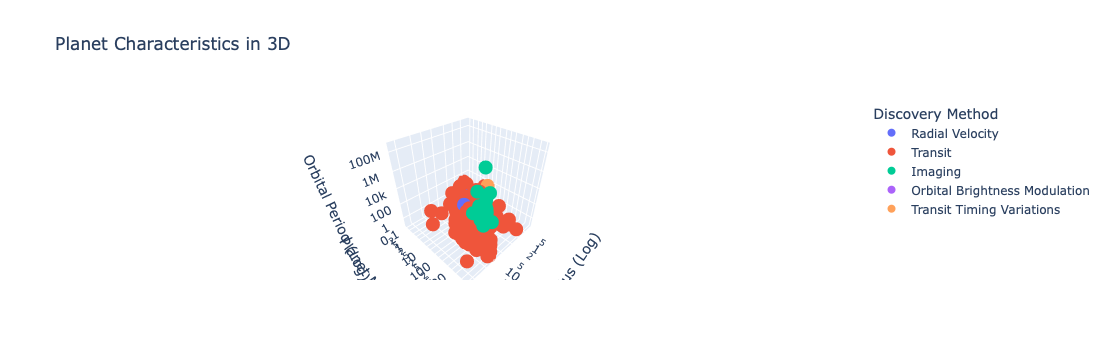

In [18]:
#Create Interactive Plot in plotly.express
import plotly.express as px
import plotly.io as pio


fig = px.scatter_3d(
    df,
    x="pl_rade",
    y="pl_bmasse",
    z="pl_orbper",
    color="discoverymethod",
    title="Planet Characteristics in 3D",
    labels={
        "pl_rade": "Planet Radius (Log)",
        "pl_bmasse": "Planet Mass (Log)",
        "pl_orbper": "Orbital Period (Log)",
        "discoverymethod": "Discovery Method"
    },
    log_x=True,
    log_y=True,
    log_z=True
)

fig.show()